# Weather-Driven Disease Risk Model
## Potato Late Blight (*Phytophthora infestans*) — Great Britain
**Author:** Junaid
**Goal:** Flag days when weather favours late blight infection, using NASA POWER weather data, the Smith Period and Hutton Criteria rules, and (if labelled data exists) machine learning.

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
import requests

pd.set_option("display.width", 140)
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
print("Libraries loaded.")

Libraries loaded.


In [2]:
SITE_NAME = "Norfolk, England"
LAT, LON = 52.45, 1.30           # any UK potato site; west is negative
YEARS = list(range(2005, 2026))  # NASA POWER hourly starts 2001
SEASON_MONTHS = [5, 6, 7, 8, 9]  # May–September

TMIN_THRESHOLD = 10.0   # °C minimum temperature
RH_THRESHOLD   = 90.0   # % relative humidity
HUTTON_HOURS   = 6      # hours RH >= 90% on each of 2 consecutive days
SMITH_HOURS    = 11     # older Smith Period requirement

## 1. Biology summary

**Pathogen:** *Phytophthora infestans*, an oomycete (water mould), not a true fungus.

**Infection cycle (repeats many times per season):**
1. **Sporulation:** infected leaves produce sporangia when RH is ≥ ~90% for several hours, usually overnight.
2. **Dispersal:** wind and rain splash carry sporangia to new leaves.
3. **Infection:** needs free water on the leaf. At ~10–15 °C sporangia release swimming zoospores; at ~20–25 °C they germinate directly.
4. **Latent period:** lesions appear 3–7 days later, then sporulate again.

**Temperature:** little activity below ~10 °C, favourable at ~15–22 °C, suppressed by hot dry spells (>28 °C).

| Feature | Biological reason |
|---|---|
| Min temp ≥ 10 °C | Nights warm enough to sporulate and infect |
| Hours RH ≥ 90% | Proxy for leaf wetness |
| Two consecutive days | Repeated sporulation-infection windows needed |
| Rolling rainfall | Splash spread, wet foliage |
| Rolling favourable days | Disease builds cycle on cycle |

**Rules:**
- **Smith Period (1956):** 2 consecutive days, each with min temp ≥ 10 °C and ≥ 11 h RH ≥ 90%.
- **Hutton Criteria (AHDB, from 2017):** same, but ≥ 6 h RH ≥ 90%. Newer pathogen strains infect in drier conditions.

**References:** Dancey (2018) PhD thesis, Univ. of Dundee/James Hutton Institute; Smith (1956) *Plant Pathology* 5:83–87; NASA Langley Research Center POWER Project.

## 2. Get weather data (NASA POWER, hourly)
Hourly T2M (°C), RH2M (%), PRECTOTCORR (mm/h). Each season is downloaded once and saved to data/.

In [3]:
POWER_URL = "https://power.larc.nasa.gov/api/temporal/hourly/point"

def download_season(year, lat=LAT, lon=LON, months=SEASON_MONTHS):
    path = f"data/power_hourly_{lat}_{lon}_{year}.csv"
    if os.path.exists(path):
        return pd.read_csv(path, parse_dates=["datetime"])

    end_month = max(months)
    end_day = pd.Period(f"{year}-{end_month:02d}").days_in_month
    params = {
        "parameters": "T2M,RH2M,PRECTOTCORR",
        "community": "AG",
        "latitude": lat, "longitude": lon,
        "start": f"{year}{min(months):02d}01",
        "end": f"{year}{end_month:02d}{end_day}",
        "format": "JSON", "time-standard": "LST",
    }
    for attempt in range(3):
        try:
            r = requests.get(POWER_URL, params=params, timeout=120)
            r.raise_for_status()
            break
        except Exception as e:
            print(f"  {year}: attempt {attempt+1} failed ({e}); retrying...")
            time.sleep(5)
    else:
        raise RuntimeError(f"Could not download {year}")

    p = r.json()["properties"]["parameter"]
    df = pd.DataFrame({k: pd.Series(v) for k, v in p.items()})
    df.index = pd.to_datetime(df.index, format="%Y%m%d%H")
    df = df.rename_axis("datetime").reset_index().replace(-999, np.nan)
    df.to_csv(path, index=False)
    time.sleep(1)
    return df

frames = []
for y in YEARS:
    print(f"Getting {y}...")
    frames.append(download_season(y))
hourly = pd.concat(frames, ignore_index=True).sort_values("datetime")
print(hourly.shape)
hourly.head()

Getting 2005...
Getting 2006...
Getting 2007...
Getting 2008...
Getting 2009...
Getting 2010...
Getting 2011...
Getting 2012...
Getting 2013...
Getting 2014...
Getting 2015...
Getting 2016...
Getting 2017...
Getting 2018...
Getting 2019...
Getting 2020...
Getting 2021...
Getting 2022...
Getting 2023...
Getting 2024...
Getting 2025...
(77112, 4)


,datetime,T2M,RH2M,PRECTOTCORR
0,2005-05-01 00:00:00,10.88,95.22,0.08
1,2005-05-01 01:00:00,11.05,94.01,0.07
2,2005-05-01 02:00:00,11.25,92.99,0.24
3,2005-05-01 03:00:00,11.25,92.55,0.56
4,2005-05-01 04:00:00,11.07,93.21,0.80


In [4]:
print("Missing values per column:")
print(hourly.isna().sum())
print(hourly[["T2M", "RH2M", "PRECTOTCORR"]].describe().round(1))

Missing values per column:
datetime       0
T2M            0
RH2M           0
PRECTOTCORR    0
dtype: int64
           T2M     RH2M  PRECTOTCORR
count  77112.0  77112.0      77112.0
mean      15.3     80.1          0.1
std        4.5     15.4          0.3
min       -0.2     35.9          0.0
25%       12.1     66.4          0.0
50%       15.1     83.7          0.0
75%       18.3     93.9          0.0
max       30.2    100.0         14.3


## 3. Daily features
Convert hourly data into one row per day: min/max/mean temperature, hours with RH ≥ 90%, mean RH and daily rainfall.

In [5]:
h = hourly.copy()
h["date"] = h["datetime"].dt.normalize()
h["humid"] = (h["RH2M"] >= RH_THRESHOLD).astype(int)

daily = h.groupby("date").agg(
    tmin=("T2M", "min"),
    tmax=("T2M", "max"),
    tmean=("T2M", "mean"),
    rh_mean=("RH2M", "mean"),
    rh_hours90=("humid", "sum"),
    rain_mm=("PRECTOTCORR", "sum"),
    n_hours=("T2M", "count"),
).reset_index()

daily = daily[daily["n_hours"] >= 20]   # drop days with many missing hours
daily["year"] = daily["date"].dt.year
daily = daily[daily["date"].dt.month.isin(SEASON_MONTHS)].reset_index(drop=True)
print(daily.shape)
daily.head(10).round(1)

(3213, 9)


C:\Users\LapFlips\AppData\Local\Temp\ipykernel_12884\1994018671.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  daily.head(10).round(1)


,date,tmin,tmax,tmean,rh_mean,rh_hours90,rain_mm,n_hours,year
0,2005-05-01,10.9,23.1,16.1,83.3,10,3.0,24,2005
1,2005-05-02,10.8,19.6,14.6,86.3,12,2.0,24,2005
2,2005-05-03,8.9,18.4,12.9,87.0,15,3.1,24,2005
3,2005-05-04,3.3,12.2,8.6,87.6,10,1.7,24,2005
4,2005-05-05,1.4,16.2,9.6,83.4,10,0.6,24,2005
5,2005-05-06,6.9,14.6,10.7,76.4,9,3.8,24,2005
6,2005-05-07,5.3,12.0,9.2,79.3,9,7.5,24,2005
7,2005-05-08,3.9,10.8,7.4,80.0,10,1.5,24,2005
8,2005-05-09,2.4,10.3,6.5,81.1,11,1.1,24,2005
9,2005-05-10,2.1,10.6,6.4,81.7,11,1.3,24,2005


## 4. Rule-based baseline: Smith Period and Hutton Criteria
A rule is met on day *d* when both day *d−1* and day *d* qualify. Only truly consecutive days are paired.
Risk levels: 0 = low, 1 = near miss, 2 = Hutton, 3 = Smith (stricter).

In [6]:
def consecutive_rule(df, min_hours, tmin=TMIN_THRESHOLD):
    qualifies = (df["tmin"] >= tmin) & (df["rh_hours90"] >= min_hours)
    prev_qualifies = qualifies.shift(1, fill_value=False)
    prev_is_yesterday = (df["date"] - df["date"].shift(1)) == pd.Timedelta(days=1)
    return (qualifies & prev_qualifies & prev_is_yesterday).astype(int)

daily["hutton"] = consecutive_rule(daily, HUTTON_HOURS)
daily["smith"]  = consecutive_rule(daily, SMITH_HOURS)

# Near miss: within 1 hour or 1 °C of Hutton on both days
near = (daily["tmin"] >= TMIN_THRESHOLD - 1) & (daily["rh_hours90"] >= HUTTON_HOURS - 1)
consec = (daily["date"] - daily["date"].shift(1)) == pd.Timedelta(days=1)
daily["near_miss"] = ((near & near.shift(1, fill_value=False) & consec)
                      & (daily["hutton"] == 0)).astype(int)

daily["risk_level"] = np.select(
    [daily["smith"] == 1, daily["hutton"] == 1, daily["near_miss"] == 1],
    [3, 2, 1], default=0)

summary = daily.groupby("year").agg(
    hutton_days=("hutton", "sum"),
    smith_days=("smith", "sum"),
    near_miss_days=("near_miss", "sum"),
    rain_total_mm=("rain_mm", "sum"),
)
summary["first_hutton"] = (daily[daily["hutton"] == 1]
                           .groupby("year")["date"].min().dt.strftime("%d %b"))
summary = summary.fillna({"first_hutton": "none"})
summary.round(0).to_csv("outputs/season_summary.csv")
summary.round(0)

,hutton_days,smith_days,near_miss_days,rain_total_mm,first_hutton
year,,,,,
2005,74,21,10,303.0,02 May
2006,76,22,17,365.0,19 May
2007,68,29,14,479.0,08 Jun
2008,68,21,24,321.0,28 May
2009,61,2,25,207.0,14 Jun
2010,51,20,28,303.0,09 Jun
2011,55,8,20,254.0,17 May
2012,54,11,18,384.0,27 May
2013,60,15,22,218.0,13 Jun


In [7]:
print(summary.to_string())

      hutton_days  smith_days  near_miss_days  rain_total_mm first_hutton
year                                                                     
2005           74          21              10         303.48       02 May
2006           76          22              17         364.68       19 May
2007           68          29              14         478.57       08 Jun
2008           68          21              24         321.07       28 May
2009           61           2              25         207.39       14 Jun
2010           51          20              28         303.22       09 Jun
2011           55           8              20         254.01       17 May
2012           54          11              18         384.03       27 May
2013           60          15              22         218.30       13 Jun
2014           62          19              24         304.47       18 May
2015           35           6              30         402.04       13 Jun
2016           79          24         

**Observation:** Hutton days are high every season (35–99 of 153 days), likely because NASA POWER is ~50 km gridded data near the coast. Season rainfall separates reported high (2012) and low (2018, 2022) blight years better than Hutton counts — consistent with rain splash dispersal and leaf wetness. To verify with AHDB/Farmers Weekly season reports.

## 5. Risk calendar
Each row is a season, each column a day from 1 May to 30 September.

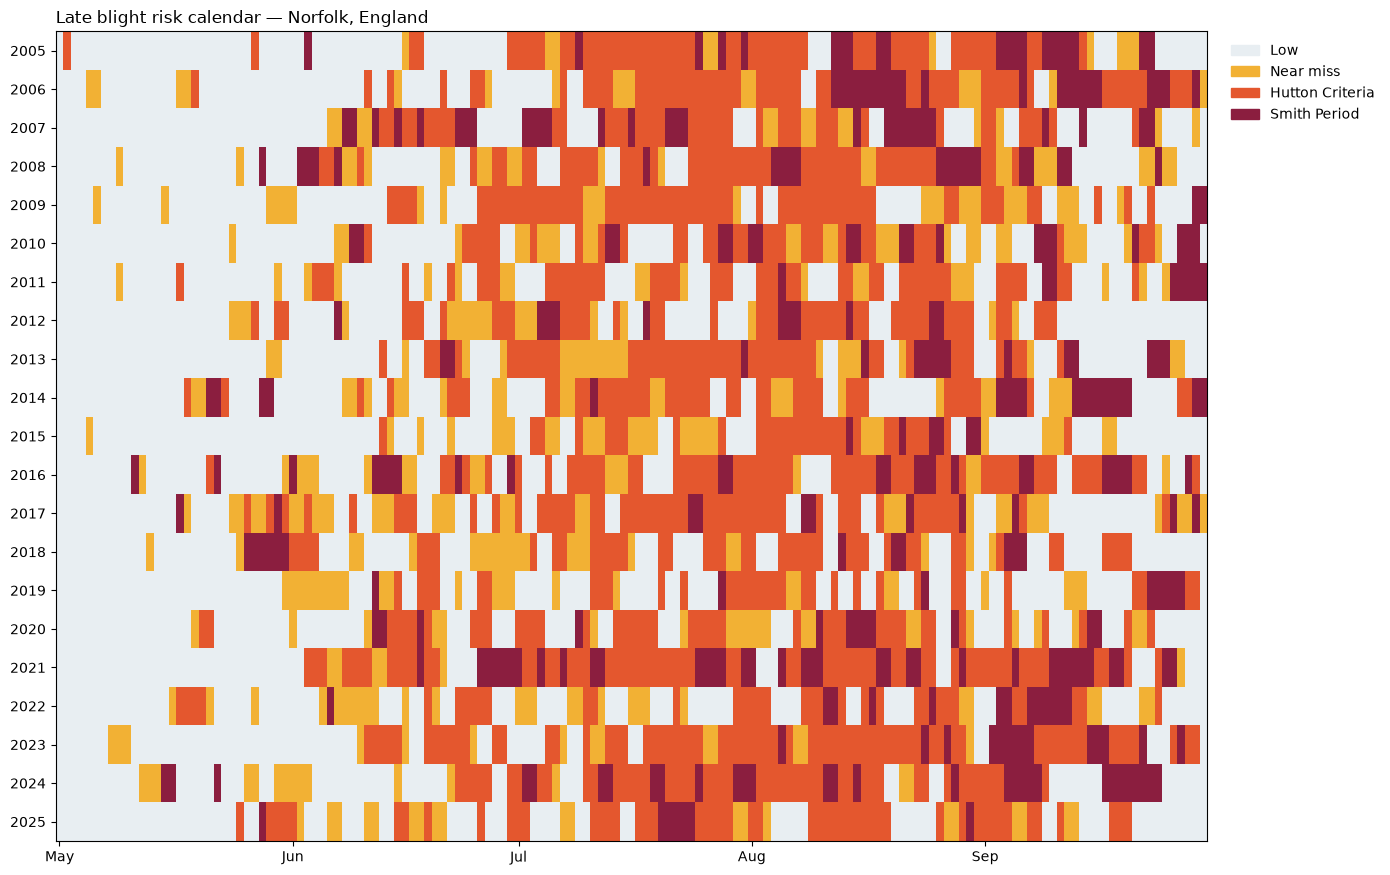

In [8]:
cal = daily.copy()
cal["doy"] = (cal["date"] - pd.to_datetime(cal["year"].astype(str) + "-05-01")).dt.days
grid = cal.pivot_table(index="year", columns="doy", values="risk_level", aggfunc="max")

cmap = mcolors.ListedColormap(["#e8eef2", "#f2b134", "#e4572e", "#8b1e3f"])
norm = mcolors.BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], cmap.N)

fig, ax = plt.subplots(figsize=(14, 0.35 * len(grid) + 1.5))
ax.imshow(grid.values, aspect="auto", cmap=cmap, norm=norm, interpolation="nearest")
ax.set_yticks(range(len(grid)))
ax.set_yticklabels(grid.index)
ax.set_xticks([0, 31, 61, 92, 123])
ax.set_xticklabels(["May", "Jun", "Jul", "Aug", "Sep"])
ax.set_title(f"Late blight risk calendar — {SITE_NAME}", loc="left")
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(cmap.colors,
          ["Low", "Near miss", "Hutton Criteria", "Smith Period"])],
          loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
plt.tight_layout()
plt.savefig("outputs/risk_calendar.png", dpi=200, bbox_inches="tight")
plt.show()

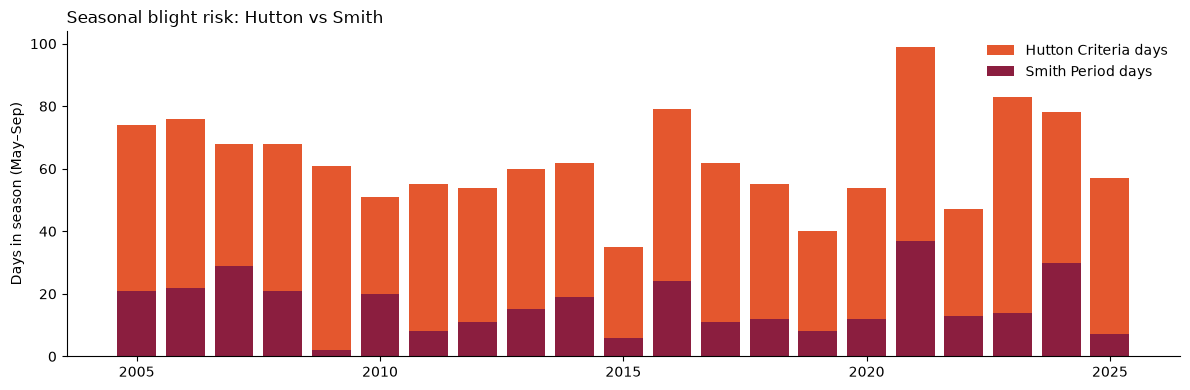

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(summary.index, summary["hutton_days"], color="#e4572e", label="Hutton Criteria days")
ax.bar(summary.index, summary["smith_days"], color="#8b1e3f", label="Smith Period days")
ax.set_ylabel("Days in season (May–Sep)")
ax.set_title("Seasonal blight risk: Hutton vs Smith", loc="left")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("outputs/seasonal_counts.png", dpi=200)
plt.show()

## 6. Validation against reality
**6a. Season-level check:** reported high/low blight years (to verify with AHDB / Farmers Weekly season reports).
**6b. Outbreak-level check:** was there a Hutton alert 7–21 days before each dated outbreak report? (Needs `data/outbreaks.csv`.)

In [19]:
KNOWN_SEASONS = {
    2007: ("high", "PotatoPro, 27 Sep 2007: record 301 confirmed outbreaks"),
    2012: ("high", "Farmers Weekly, 15 Aug 2012: 335 outbreaks by mid-Aug, extreme pressure"),
    2018: ("low",  "FAS Crop Health Update, Jul 2018: very few cases, dry conditions"),
    2021: ("high", "Agriland, 8 Jul 2021: weather favoured blight (Scotland-focused)"),
    2022: ("low",  "Farmers Guardian, 26 Aug 2022: 37 outbreaks mapped despite dry summer"),
    2023: ("high", "Farm Contractor, 21 Aug 2023: 120 outbreaks by mid-Aug, wettest July since 2009"),
}

val = summary.copy()
val["rain_rank"] = val["rain_total_mm"].rank(ascending=False).astype(int)
val["reported_pressure"] = [KNOWN_SEASONS.get(y, ("", ""))[0] for y in val.index]
val["source"] = [KNOWN_SEASONS.get(y, ("", ""))[1] for y in val.index]
checked = val[val["reported_pressure"] != ""]
display(checked[["hutton_days", "smith_days", "rain_total_mm", "rain_rank",
                 "first_hutton", "reported_pressure", "source"]])

means = {"hutton_days": summary["hutton_days"].mean(),
         "smith_days": summary["smith_days"].mean(),
         "rain_total_mm": summary["rain_total_mm"].mean()}
for col, m in means.items():
    hits = sum((row[col] > m) == (row["reported_pressure"] == "high")
               for _, row in checked.iterrows())
    print(f"{col:15s}: agrees with {hits}/{len(checked)} reported seasons (average = {m:.1f})")

,hutton_days,smith_days,rain_total_mm,rain_rank,first_hutton,reported_pressure,source
year,,,,,,,
2007,68,29,478.57,1,08 Jun,high,"PotatoPro, 27 Sep 2007: record 301 confirmed o..."
2012,54,11,384.03,4,27 May,high,"Farmers Weekly, 15 Aug 2012: 335 outbreaks by ..."
2018,55,12,184.20,20,26 May,low,"FAS Crop Health Update, Jul 2018: very few cas..."
2021,99,37,321.25,9,03 Jun,high,"Agriland, 8 Jul 2021: weather favoured blight ..."
2022,47,13,206.05,19,17 May,low,"Farmers Guardian, 26 Aug 2022: 37 outbreaks ma..."
2023,83,14,312.50,11,11 Jun,high,"Farm Contractor, 21 Aug 2023: 120 outbreaks by..."


hutton_days    : agrees with 5/6 reported seasons (average = 62.8)
smith_days     : agrees with 4/6 reported seasons (average = 16.3)
rain_total_mm  : agrees with 6/6 reported seasons (average = 308.1)


In [16]:
OUTBREAK_FILE = "data/outbreaks.csv"
LOOKBACK_MIN, LOOKBACK_MAX = 7, 21

if os.path.exists(OUTBREAK_FILE):
    ob = pd.read_csv(OUTBREAK_FILE, parse_dates=["date"])
    hutton_dates = set(daily.loc[daily["hutton"] == 1, "date"])
    smith_dates  = set(daily.loc[daily["smith"] == 1, "date"])
    def had_alert(d, dates):
        window = pd.date_range(d - pd.Timedelta(days=LOOKBACK_MAX),
                               d - pd.Timedelta(days=LOOKBACK_MIN))
        return any(x in dates for x in window)
    ob["hutton_alert_before"] = ob["date"].apply(lambda d: had_alert(d, hutton_dates))
    ob["smith_alert_before"]  = ob["date"].apply(lambda d: had_alert(d, smith_dates))
    display(ob)
    print(f"Hutton hit rate: {ob['hutton_alert_before'].mean():.0%} | "
          f"Smith hit rate: {ob['smith_alert_before'].mean():.0%} (n = {len(ob)})")
else:
    print("No outbreaks.csv found — outbreak validation skipped. State this in your write-up.")

No outbreaks.csv found — outbreak validation skipped. State this in your write-up.


## 7. Machine learning (needs real disease labels)
Runs only if `data/labels.csv` exists (columns: `date,disease`). Hutton flags are **not** used as labels — the model would just relearn the rule.

In [17]:
feat = daily.sort_values("date").copy()
fav = ((feat["tmin"] >= TMIN_THRESHOLD) & (feat["rh_hours90"] >= HUTTON_HOURS)).astype(int)

def roll(s, w, fn="mean"):
    return s.groupby(feat["year"]).transform(
        lambda x: getattr(x.rolling(w, min_periods=1), fn)())

feat["tmin_roll3"]      = roll(feat["tmin"], 3)
feat["tmin_roll7"]      = roll(feat["tmin"], 7)
feat["tmax_roll7"]      = roll(feat["tmax"], 7)
feat["rh90h_roll3"]     = roll(feat["rh_hours90"], 3, "sum")
feat["rh90h_roll7"]     = roll(feat["rh_hours90"], 7, "sum")
feat["rain_roll7"]      = roll(feat["rain_mm"], 7, "sum")
feat["fav_days_7"]      = roll(fav, 7, "sum")
feat["hutton_count_14"] = roll(feat["hutton"], 14, "sum")
feat["doy"]             = feat["date"].dt.dayofyear

FEATURES = ["tmin_roll3", "tmin_roll7", "tmax_roll7", "rh90h_roll3", "rh90h_roll7",
            "rain_roll7", "fav_days_7", "hutton_count_14", "doy"]
feat[["date"] + FEATURES].tail().round(1)

C:\Users\LapFlips\AppData\Local\Temp\ipykernel_12884\1214633650.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  feat[["date"] + FEATURES].tail().round(1)


,date,tmin_roll3,tmin_roll7,tmax_roll7,rh90h_roll3,rh90h_roll7,rain_roll7,fav_days_7,hutton_count_14,doy
3208,2025-09-26,9.4,9.4,16.8,5.0,17.0,3.1,1.0,3.0,269
3209,2025-09-27,8.9,9.0,16.5,18.0,22.0,2.2,0.0,3.0,270
3210,2025-09-28,9.1,9.0,16.9,31.0,35.0,2.4,0.0,3.0,271
3211,2025-09-29,8.8,9.0,17.3,34.0,43.0,2.5,0.0,3.0,272
3212,2025-09-30,8.2,8.8,17.6,32.0,50.0,1.0,0.0,3.0,273


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, classification_report

LABEL_FILE = "data/labels.csv"

if os.path.exists(LABEL_FILE):
    labels = pd.read_csv(LABEL_FILE, parse_dates=["date"])
    data = feat.merge(labels, on="date", how="inner").dropna(subset=FEATURES)
    print(f"{len(data)} labelled days, {data['disease'].sum()} positives")

    # Split by YEAR, not randomly (days in a season are correlated)
    years = sorted(int(y) for y in data["year"].unique())
    n_test = max(1, round(len(years) * 0.3))
    test_years = years[-n_test:]
    train = data[~data["year"].isin(test_years)]
    test  = data[data["year"].isin(test_years)]
    print("Train years:", years[:-n_test], "| Test years:", test_years)

    models = {
        "Logistic regression": make_pipeline(StandardScaler(),
            LogisticRegression(class_weight="balanced", max_iter=1000)),
        "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
            class_weight="balanced", random_state=42),
    }
    for name, m in models.items():
        m.fit(train[FEATURES], train["disease"])
        prob = m.predict_proba(test[FEATURES])[:, 1]
        print(f"\n=== {name} ===")
        if test["disease"].nunique() > 1:
            print(f"ROC-AUC: {roc_auc_score(test['disease'], prob):.2f}")
        print(classification_report(test["disease"], (prob >= 0.5).astype(int), zero_division=0))

    print("=== Hutton rule baseline ===")
    print(classification_report(test["disease"],
          (test["hutton_count_14"] > 0).astype(int), zero_division=0))

    imp = pd.Series(models["Random forest"].feature_importances_, index=FEATURES).sort_values()
    imp.plot.barh(figsize=(7, 4), color="#4c78a8", title="Random forest feature importance")
    plt.tight_layout(); plt.savefig("outputs/feature_importance.png", dpi=200); plt.show()
else:
    print("No labels.csv found — ML skipped. A validated rule-based model is still a complete project.")

No labels.csv found — ML skipped. A validated rule-based model is still a complete project.


## 8. What was and wasn't validated

| Check | Done? | Result |
|---|---|---|
| Rules coded as published (Smith 1956; Hutton, Dancey 2018) | ✅ | Thresholds in CONFIG; logic unit-tested |
| Season-level agreement with reported high/low years | ✅ (6 seasons, published sources) | Hutton 5/6, Smith 4/6, rainfall 6/6; both rules miss 2012 |
| Outbreak hit rate (alert 7–21 days before report) | ❌ | No dated outbreak records found |
| ML trained on real disease labels | ❌ | No labelled data; features and models ready to run |

**Limitations:**
- NASA POWER is gridded (~50 km), not an in-field station. At this coastal Norfolk point, humid hours are frequent, so the Hutton Criteria flag 35–99 of 153 days per season — far more than an operational warning service would issue.
- The rules estimate weather suitability, not disease. Inoculum, variety resistance and fungicide use also matter.
- Season-level validation with six years is weak evidence, and one grid point misses regional risk (e.g. 2012).

**Next steps:** compare with a Met Office MIDAS station near the site; test an inland site; add a rainfall condition to the rule; obtain dated outbreak records from AHDB for outbreak-level validation.

In [18]:
daily.to_csv("outputs/daily_risk.csv", index=False)
print("Saved: daily_risk.csv, season_summary.csv, risk_calendar.png, seasonal_counts.png")

Saved: daily_risk.csv, season_summary.csv, risk_calendar.png, seasonal_counts.png
